In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout
from tensorflow.keras.callbacks import EarlyStopping
import keras_tuner as kt

In [100]:
df = pd.read_csv("/content/mobile_price_classification.csv")
df.head()

,battery_power,bluetooth,clock_speed,dual_sim,front_cam,4G,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [101]:
df.shape

(2000, 21)

In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   battery_power   2000 non-null   int64  
 1   bluetooth       2000 non-null   int64  
 2   clock_speed     2000 non-null   float64
 3   dual_sim        2000 non-null   int64  
 4   front_cam       2000 non-null   int64  
 5   4G              2000 non-null   int64  
 6   int_memory      2000 non-null   int64  
 7   m_dep           2000 non-null   float64
 8   mobile_wt       2000 non-null   int64  
 9   n_cores         2000 non-null   int64  
 10  primary_camera  2000 non-null   int64  
 11  px_height       2000 non-null   int64  
 12  px_width        2000 non-null   int64  
 13  ram             2000 non-null   int64  
 14  sc_h            2000 non-null   int64  
 15  sc_w            2000 non-null   int64  
 16  talk_time       2000 non-null   int64  
 17  three_g         2000 non-null   i

In [103]:
df.isnull().sum()             # No null Values

,0
battery_power,0
bluetooth,0
clock_speed,0
dual_sim,0
front_cam,0
4G,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


In [104]:
df.duplicated().sum()  # No Duplicates

np.int64(0)

In [105]:
df['price_range'].value_counts()

,count
price_range,
1,500
2,500
3,500
0,500


In [106]:
# Selecting Features and Target
X = df.drop('price_range', axis=1)
y = df['price_range']

In [107]:
# Spliting
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [108]:
# Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [109]:
# Build the Model    20-Inputs,  4- Outputs
model = Sequential([
    Dense(64, input_shape=(20,), activation='relu'),
    Dense(32, activation='relu'),
    Dense(4, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [110]:
# Compile
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [111]:
# Train
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(X_train,y_train,epochs=100,batch_size=32,validation_split=0.2,callbacks=[early_stop],verbose=1)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3555 - loss: 1.3384 - val_accuracy: 0.4437 - val_loss: 1.2358
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5320 - loss: 1.1122 - val_accuracy: 0.5875 - val_loss: 1.0168
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6602 - loss: 0.8835 - val_accuracy: 0.6781 - val_loss: 0.8035
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7523 - loss: 0.6932 - val_accuracy: 0.7563 - val_loss: 0.6481
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8180 - loss: 0.5580 - val_accuracy: 0.8344 - val_loss: 0.5328
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8758 - loss: 0.4584 - val_accuracy: 0.8687 - val_loss: 0.4499
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9047 - loss: 0.3849 - val_accuracy: 0.8781 - val_loss: 0.3872
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9266 - loss: 0.3255 - val_accuracy: 0.8875 - v

In [112]:
# Evaluate ANN model
loss,accuracy = model.evaluate(X_test,y_test)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy*100:.2f}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9050 - loss: 0.2041  
Test Loss: 0.2041
Test Accuracy: 90.50%


In [113]:
# Prediction
y_pred = np.argmax(model.predict(X_test),axis=1)
print(classification_report(y_test,y_pred))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       100
           1       0.86      0.87      0.87       100
           2       0.87      0.90      0.89       100
           3       0.95      0.94      0.94       100

    accuracy                           0.91       400
   macro avg       0.91      0.91      0.91       400
weighted avg       0.91      0.91      0.91       400



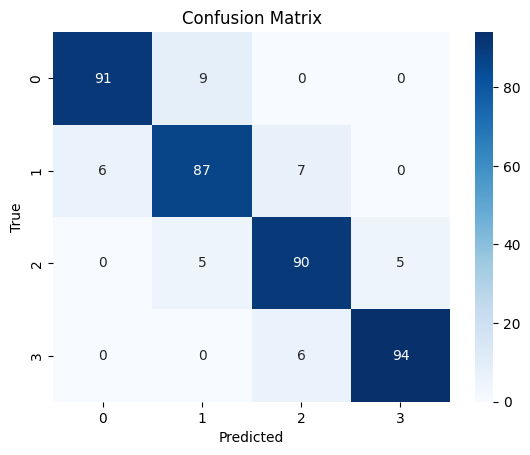

In [114]:
# Confusion Matrix
cm = confusion_matrix(y_test,y_pred)

sns.heatmap(cm,annot=True,fmt='d',cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

Hyperparameter tuning using RandomSearch

In [115]:
# building model and compile inside a def function

def build_model(hp):

    model = Sequential()

    # Input and first hidden layer
    model.add(Dense(units=hp.Int('units_1',min_value=16,max_value=128,step=16),input_shape=(20,),activation='relu'))

    # Hyperparameter for dropout
    dropout_rate = hp.Float('dropout',min_value=0.0,max_value=0.4,step=0.1)

    model.add(Dropout(dropout_rate))

    # Tune number of hidden layers
    for i in range(hp.Int('num_layers', 1, 3)):
      model.add(Dense(units=hp.Int(f'units_{i+2}',min_value=16,max_value=128,step=16),activation='relu'))

    # Output layer
    model.add(Dense(4, activation='softmax'))

    # Tune learning rate
    learning_rate = hp.Choice('learning_rate',values=[0.01, 0.001, 0.0001])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

    return model

In [116]:
# Initialize RandomSearch
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=15,
    executions_per_trial=1,
    directory='mobile_tuning',
    project_name='mobile_price'
)

Reloading Tuner from mobile_tuning/mobile_price/tuner0.json


In [117]:
# Perform hyperparameter tuning in Training
tuner.search(X_train,y_train,epochs=50,batch_size=32,validation_split=0.2,callbacks=[early_stop],verbose=1)



In [118]:
# Get the best hyperparameters
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

In [119]:
# Show the Best Hyperparameters
print("Best Hyperparameters:")
print("First Hidden Layer:", best_hp.get("units_1"))
print("Number of HIdden Layers:", best_hp.get("num_layers"))
print("Dropout Rate:", best_hp.get("dropout"))
print("Learning Rate:", best_hp.get("learning_rate"))

Best Hyperparameters:
First Hidden Layer: 128
Number of HIdden Layers: 3
Dropout Rate: 0.1
Learning Rate: 0.001


In [120]:
# Build the Best Model
best_model = tuner.get_best_models(num_models=1)[0]

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [121]:
# Train the Best Model
history_best = best_model.fit(X_train,y_train,epochs=100,batch_size=32,validation_split=0.2,callbacks=[early_stop],verbose=1)


Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9086 - loss: 0.2284 - val_accuracy: 0.9187 - val_loss: 0.2210
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9234 - loss: 0.1924 - val_accuracy: 0.9219 - val_loss: 0.1920
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9398 - loss: 0.1574 - val_accuracy: 0.9344 - val_loss: 0.1679
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9367 - loss: 0.1549 - val_accuracy: 0.9281 - val_loss: 0.1775
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9594 - loss: 0.1278 - val_accuracy: 0.9312 - val_loss: 0.1656
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9547 - loss: 0.1135 - val_accuracy: 0.9156 - val_loss: 0.1711
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9523 - loss: 0.1101 - val_accuracy: 0.9281 - val_loss: 0.1927
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9523 - loss: 0.1183 - val_accuracy: 0.9219 - 

In [122]:
# Evaluate the Best Model
result = best_model.evaluate(X_test,y_test)
print(f"Test Loss: {result[0]:.4f}")
print(f"Test Accuracy: {result[1]*100:.2f}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9225 - loss: 0.2157  
Test Loss: 0.2157
Test Accuracy: 92.25%


In [123]:
# Make prediction
y_pred = np.argmax(best_model.predict(X_test),axis=1)
y_true = y_test
print(classification_report(y_test,y_pred))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
              precision    recall  f1-score   support

           0       0.95      0.95      0.95       100
           1       0.88      0.93      0.90       100
           2       0.92      0.87      0.89       100
           3       0.95      0.94      0.94       100

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



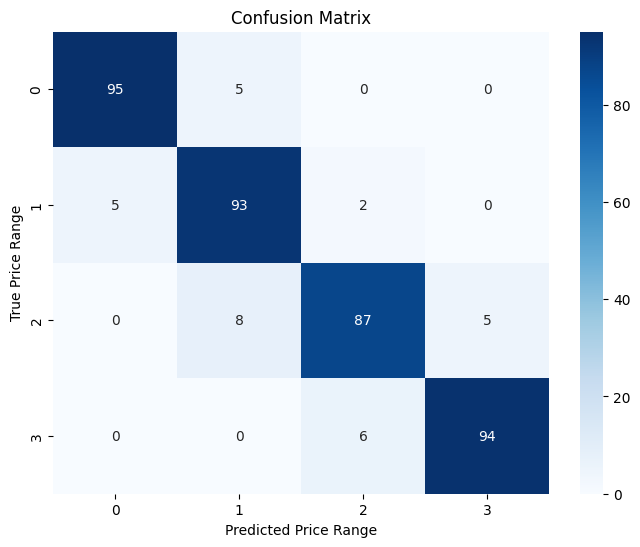

In [124]:
# Confusion matrix:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt='d',cmap="Blues")
plt.xlabel("Predicted Price Range")
plt.ylabel("True Price Range")
plt.title("Confusion Matrix")
plt.show()

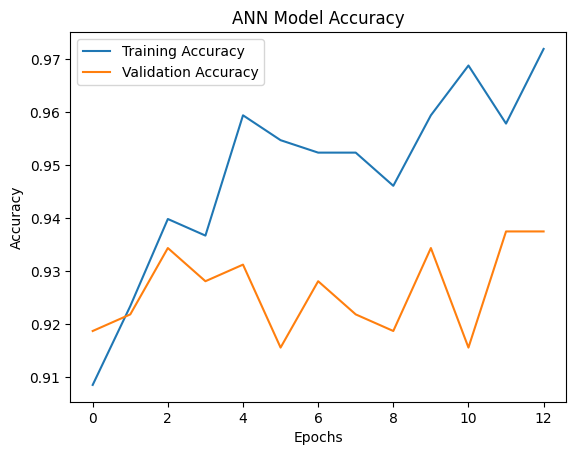

In [129]:
# Plot accuracy and loss
plt.plot(history_best.history['accuracy'],label='Training Accuracy')

plt.plot(history_best.history['val_accuracy'],label='Validation Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.title('ANN Model Accuracy')

plt.legend()
plt.show()

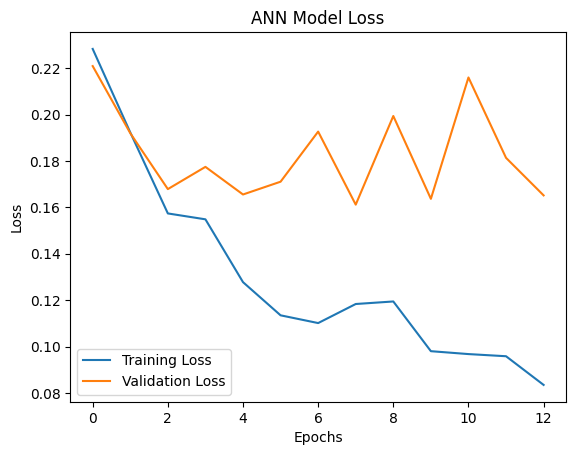

In [130]:
# Training vs validation loss

plt.plot(history_best.history['loss'],label='Training Loss')

plt.plot(history_best.history['val_loss'],label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.title('ANN Model Loss')

plt.legend()
plt.show()

In [131]:
# Compare basic ANN and tuned ANN
basic_results = model.evaluate(X_test, y_test, verbose=0)

tuned_results = best_model.evaluate(X_test, y_test, verbose=0)

comparison = pd.DataFrame({'Model': ['Basic ANN', 'Tuned ANN'],'Test Loss': [basic_results[0],tuned_results[0]],'Test Accuracy': [basic_results[1],tuned_results[1]]})

print(comparison)

       Model  Test Loss  Test Accuracy
0  Basic ANN   0.204134         0.9050
1  Tuned ANN   0.215749         0.9225


Conclution

In [ ]:
# The tuned model can help Bob understand the relationship between mobile phone specifications and their price categories.